<img src='http://drive.google.com/uc?export=view&id=1UAsSD6z0wK4UJjjzBhDEIlSZnELLmeeb'>

# <font color='lightblue'>Answering Questions</font>

In this project we will:

1.  Introduce the question of interest
2.  Ensure the reader knows enough about the data
3.  Wrangle and preprocess the data so that anyone can reproduce the work
4.  Build and test a model that can provide insight into the question
5.  Interpret the model results
6.  Answer the question



This project will be centered around the following:

Which vehicle characteristics are linked to higher levels of CO2 Emissions?
Outcome: The ideal outcome would determine which characteristics/variables are linked to higher levels of CO2 emissions. This way we research and suggest vehicle characteristic replacements to lower the carbon footprint in Canada.

 The data source we will be using is from CO2 Emissions Canada and the dataset is from Kaggle. The dataset is very detailed and descriptive, it includes numerous amount of variables and therefore allows us to extract details we want to include or not thus providing detailed relations to vehicles and their car parts and their correlation to CO2 emissions. Data Accuracy: Our chosen dataset has no missing values which makes it very reliable and informative to work with. An important fact to keep in mind is that this dataset excludes buses and heavy-duty trucks.

This is a supervised learning problem because the data includes a known target which is the CO2 emissions and since CO2 emissions are considered as continuous numerical value, it is a regression problem. We used the Random Forest Regressor since it handles non-linear relationship, the Linear Regression and clustering to explore each characteristic and how it might influence our main question.

## <font color='lightblue'>2. Data understanding, exploration, and visualization </font>

In [95]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import numpy as np
import sklearn as sk

from sklearn import cluster
from sklearn.preprocessing import StandardScaler
import sklearn as sk
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [96]:
path = kagglehub.dataset_download("isaacfemiogunniyi/co2-emission-of-vehicles-in-canada")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'co2-emission-of-vehicles-in-canada' dataset.
Path to dataset files: /kaggle/input/co2-emission-of-vehicles-in-canada


In [97]:
df = pd.read_csv(path + "/CO2 Emissions_Canada.csv")
df

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
...,...,...,...,...,...,...,...,...,...,...,...,...
7380,VOLVO,XC40 T5 AWD,SUV - SMALL,2.0,4,AS8,Z,10.7,7.7,9.4,30,219
7381,VOLVO,XC60 T5 AWD,SUV - SMALL,2.0,4,AS8,Z,11.2,8.3,9.9,29,232
7382,VOLVO,XC60 T6 AWD,SUV - SMALL,2.0,4,AS8,Z,11.7,8.6,10.3,27,240
7383,VOLVO,XC90 T5 AWD,SUV - STANDARD,2.0,4,AS8,Z,11.2,8.3,9.9,29,232


In [98]:
for column in df.columns:
    if df[column].dtype == "object" or column == "Cylinders":
        print(column + ": Categorical")
    else:
        print(column + ": Numerical")

Make: Categorical
Model: Categorical
Vehicle Class: Categorical
Engine Size(L): Numerical
Cylinders: Categorical
Transmission: Categorical
Fuel Type: Categorical
Fuel Consumption City (L/100 km): Numerical
Fuel Consumption Hwy (L/100 km): Numerical
Fuel Consumption Comb (L/100 km): Numerical
Fuel Consumption Comb (mpg): Numerical
CO2 Emissions(g/km): Numerical


The dataset contains both categorical and numerical variables describing different vehicles. The categorical variables include Make, Model, Vehicle Class, Cylinders, Transmission, and Fuel Type, which describe the characteristics and types of vehicles. The numerical variables include Engine Size (L), Fuel Consumption City, Fuel Consumption Hwy, Fuel Consumption Comb (L/100 km), Fuel Consumption Comb (mpg), and CO₂ Emissions (g/km).

The numerical variables are important because they allow us to examine differences in vehicle performance, fuel efficiency, and environmental impact. Engine Size indicates the size of the vehicle's engine, while the city, highway, and combined fuel consumption variables measure how much fuel vehicles use under different driving conditions. CO₂ Emissions measures the amount of carbon dioxide produced per kilometre and can be used to assess the environmental impact of each vehicle.

In [99]:
numerical_cols = df.select_dtypes(include="number").columns.drop("Cylinders")  # Cylinders is categorical variable
# print(numerical_cols)

summary = df[numerical_cols].describe().T
summary["variance"] = df[numerical_cols].var()
summary["IQR"] = df[numerical_cols].quantile(0.75) - df[numerical_cols].quantile(0.25)
summary

,count,mean,std,min,25%,50%,75%,max,variance,IQR
Engine Size(L),7385.0,3.160068,1.354170,0.9,2.0,3.0,3.7,8.4,1.833778,1.7
Fuel Consumption City (L/100 km),7385.0,12.556534,3.500274,4.2,10.1,12.1,14.6,30.6,12.251919,4.5
Fuel Consumption Hwy (L/100 km),7385.0,9.041706,2.224456,4.0,7.5,8.7,10.2,20.6,4.948206,2.7
Fuel Consumption Comb (L/100 km),7385.0,10.975071,2.892506,4.1,8.9,10.6,12.6,26.1,8.366593,3.7
Fuel Consumption Comb (mpg),7385.0,27.481652,7.231879,11.0,22.0,27.0,32.0,69.0,52.300076,10.0
CO2 Emissions(g/km),7385.0,250.584699,58.512679,96.0,208.0,246.0,288.0,522.0,3423.733650,80.0


Here we have some summary statistics, including the mean, minimum, maximum, standard deviation, variance, and IQR.  
The average vehicle in our dataset has a 3.16L engine (std 1.35L), and emits 250.6 g/km of CO2 (std 58.5). The spread in CO2 emissions is
large relative to the mean. Vehicles range from 96 to 522 g/km suggesting
substantial variation driven by vehicle characteristics, which is what we explore
in the sections that follow.
Also, from the data, we can see that the fuel consumption is lower in highways than in the city.

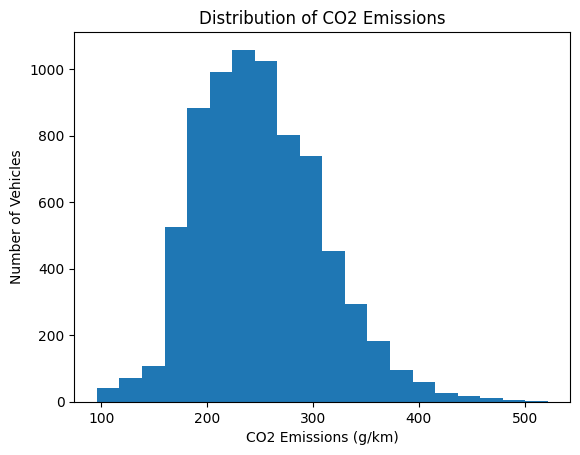

In [100]:
plt.hist(df['CO2 Emissions(g/km)'], bins=20)
plt.xlabel('CO2 Emissions (g/km)')
plt.ylabel('Number of Vehicles')
plt.title('Distribution of CO2 Emissions')
plt.show()

CO2 emissions are roughly bell-shaped with a slight right skew. Most vehicles
cluster between 180-320 g/km, with a smaller number of high-emission vehicles
(large SUVs, vans) pulling the tail upward.

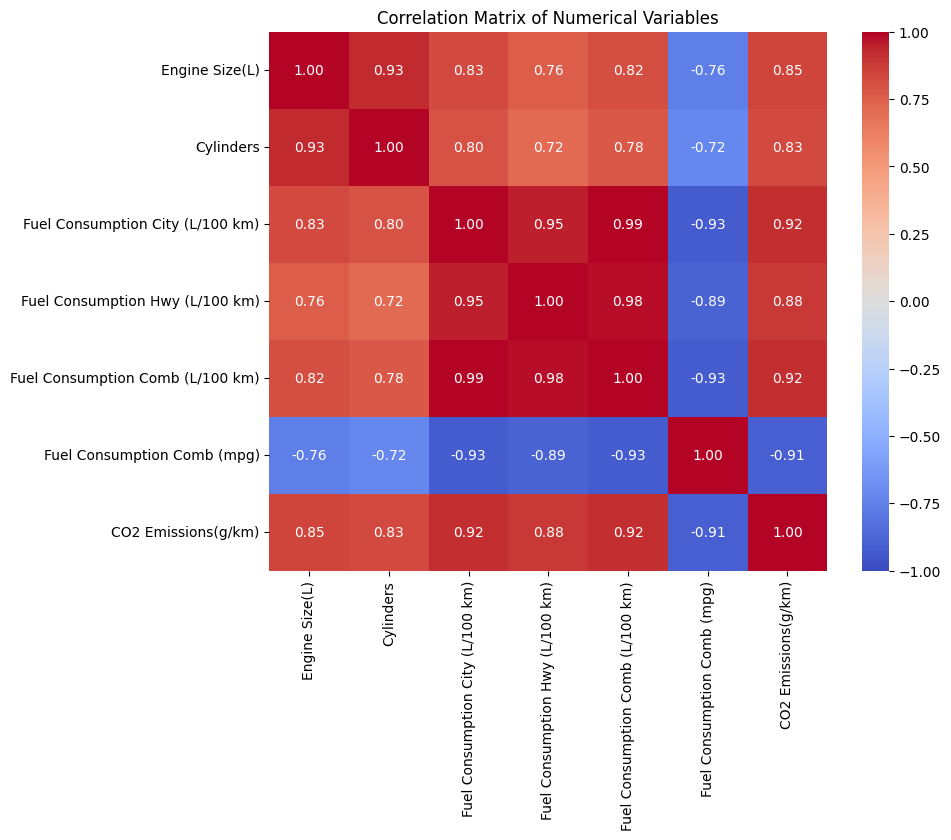

In [102]:
numerical_cols = ['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)',
                   'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)',
                   'Fuel Consumption Comb (mpg)', 'CO2 Emissions(g/km)']

corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlation Matrix of Numerical Variables')
plt.show()

The correlation matrix shows that all three L/100 km fuel consumption measures are
very strongly positively correlated with CO2 Emissions (r ≈ 0.9-0.99), which makes
physical sense as burning more fuel per distance travelled directly produces more
CO2. Fuel Consumption Comb (mpg) is strongly negatively correlated with CO2
(r ≈ -0.9), since mpg is the inverse measure; higher mpg means less fuel burned,
and therefore less CO2. Engine Size and Cylinders are both moderately-to-strongly
positively correlated with CO2 (r ≈ 0.7-0.85) and with each other (r ≈ 0.8),
consistent with larger, higher-cylinder engines consuming more fuel.

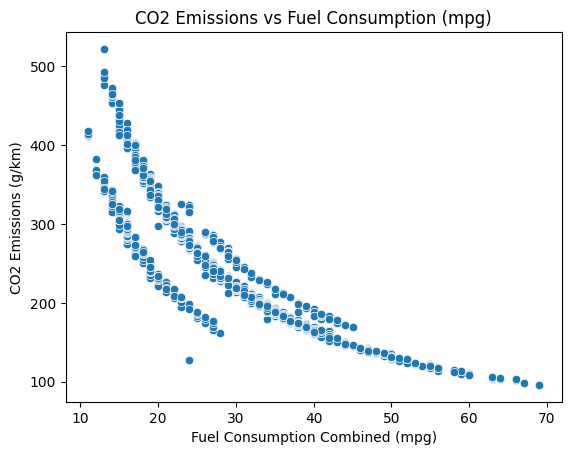

In [103]:
sns.scatterplot(data=df, x='Fuel Consumption Comb (mpg)', y='CO2 Emissions(g/km)')
plt.title('CO2 Emissions vs Fuel Consumption (mpg)')
plt.xlabel('Fuel Consumption Combined (mpg)')
plt.ylabel('CO2 Emissions (g/km)')
plt.show()

The scatterplot shows CO2 emissions decrease sharply as fuel efficiency (mpg) increases, following a
curved (non-linear) pattern rather than a straight line. The drop in emissions
is steepest between roughly 15-30 mpg and flattens out at higher mpg values.


## <font color='lightblue'>3. Data wrangling and preprocessing </font>

For preprocessing, we first checked the dataset for missing or N/A values in each column. We also checked for duplicate rows. There are duplicate observations present, so we are removing them because exact duplicate records do not provide any additional information and could cause certain observations to have a disproportionate influence on our models.

In [104]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(1103)

In [105]:
df = df.drop_duplicates() # remove dupes
print(f"Rows after removing duplicates: {len(df)}")

Rows after removing duplicates: 6282


We found 1,103 duplicate rows and removed them before any further analysis, so they don't
inflate the apparent sample size or bias summary statistics toward
over-represented vehicles.

In [106]:
df.duplicated().sum()

np.int64(0)

In [107]:
# Checking for missing values
df.isnull().sum()

,0
Make,0
Model,0
Vehicle Class,0
Engine Size(L),0
Cylinders,0
Transmission,0
Fuel Type,0
Fuel Consumption City (L/100 km),0
Fuel Consumption Hwy (L/100 km),0
Fuel Consumption Comb (L/100 km),0


 As shown above, these are some categorical variables that are strings. In order to use these features in our model, since Scikit-learn does not support categorical variables in the random forest regressor, we need to use LabelEncoder() to turn the names into integers.



In [124]:
df['Vehicle Class'] = LabelEncoder().fit_transform(df['Vehicle Class'])
df['Fuel Type'] = LabelEncoder().fit_transform(df['Fuel Type'])
df['Transmission'] = LabelEncoder().fit_transform(df['Transmission'])
df.head()

/tmp/ipykernel_3108/2312898234.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Vehicle Class'] = LabelEncoder().fit_transform(df['Vehicle Class'])
/tmp/ipykernel_3108/2312898234.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Fuel Type'] = LabelEncoder().fit_transform(df['Fuel Type'])
/tmp/ipykernel_3108/2312898234.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the d

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,0,2.0,4,14,4,9.9,6.7,8.5,33,196
1,ACURA,ILX,0,2.4,4,25,4,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,0,1.5,4,22,4,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,11,3.5,6,15,4,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,11,3.5,6,15,4,12.1,8.7,10.6,27,244


## <font color='lightblue'>4. Build and test a model</font>



In [109]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


targetcols= "CO2 Emissions(g/km)"
drop_cols = ["Fuel Consumption City (L/100 km)", "Fuel Consumption Hwy (L/100 km)",
             "Fuel Consumption Comb (L/100 km)", "Fuel Consumption Comb (mpg)", "Model", "Make"]

# For linear regression of 1 variable
x_1 = df[['Fuel Consumption Comb (mpg)']]
y_1 = df['CO2 Emissions(g/km)']

x = df.drop(columns=[targetcols] + drop_cols)
y = df[targetcols]
#Above lines allow us to exclude the 3 fuel columns so they don't give up the answer and only focus on the variables we are working with, which is Make, Model, Vehicle Class, Engine Size, Cylinders, Transmission, Fuel Type and Fuel Consumption Comb (mpg).

X_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=30)
X_train_1, x_test_1, y_train_1, y_test_1 = sk.model_selection.train_test_split(x_1, y_1, test_size=0.3, random_state=30)
#From data preprocessing project 2

Although Make, Model, and the fuel consumption columns remain in the cleaned
dataset, we excluded them from our model's feature set for these reasons:
Model has 2,000+ unique values and would impose a meaningless numeric order via
LabelEncoder, Make has a similar but less severe issue, and fuel consumption columns
are outcomes of vehicle design rather than design characteristics themselves,
which is what our question asks about.

In [110]:
from sklearn.linear_model import LinearRegression

# Linear regression model of fuel consump vs C02 emissions
lr_model_1 = LinearRegression()
lr_model_1.fit(X_train_1, y_train_1)

print("Model trained successfully!")
print(X_train_1)
print(y_train_1)

Model trained successfully!
      Fuel Consumption Comb (mpg)
6880                           19
2818                           30
4319                           43
5505                           25
5489                           29
...                           ...
5970                           27
500                            24
4154                           38
5025                           15
6723                           20

[4397 rows x 1 columns]
6880    354
2818    218
4319    155
5505    270
5489    224
       ... 
5970    242
500     276
4154    176
5025    454
6723    332
Name: CO2 Emissions(g/km), Length: 4397, dtype: int64


As a point of comparison, we also a single-feature model using only
Fuel Consumption Comb (mpg), which scored R² = 0.8146. This confirms mpg alone
carries strong predictive power but since mpg is a downstream outcome rather
than a design characteristic, we excluded it from our main model to
keep our answer actionable for vehicle design decisions.

In [111]:
# Train the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("Model trained successfully!")
print(X_train)
print(y_train)

Model trained successfully!
      Vehicle Class  Engine Size(L)  Cylinders  Transmission  Fuel Type
6880              6             5.3          8             3          3
2818             11             2.4          4            24          3
4319              0             1.5          4            15          3
5505             11             3.0          6            17          4
5489              2             3.0          6             9          4
...             ...             ...        ...           ...        ...
5970             13             3.0          6            17          4
500              11             3.5          6             2          3
4154              2             2.5          4            19          3
5025             13             6.5         12             9          4
6723              6             6.2          8             0          4

[4397 rows x 5 columns]
6880    354
2818    218
4319    155
5505    270
5489    224
       ... 
5970    242

In [112]:
# Train the Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print("Model trained successfully!")
print(X_train)
print(y_train)

Model trained successfully!
      Vehicle Class  Engine Size(L)  Cylinders  Transmission  Fuel Type
6880              6             5.3          8             3          3
2818             11             2.4          4            24          3
4319              0             1.5          4            15          3
5505             11             3.0          6            17          4
5489              2             3.0          6             9          4
...             ...             ...        ...           ...        ...
5970             13             3.0          6            17          4
500              11             3.5          6             2          3
4154              2             2.5          4            19          3
5025             13             6.5         12             9          4
6723              6             6.2          8             0          4

[4397 rows x 5 columns]
6880    354
2818    218
4319    155
5505    270
5489    224
       ... 
5970    242

In [113]:
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [114]:
y_pred_lr = lr_model_1.predict(x_test_1)
r2_lr = r2_score(y_test_1, y_pred_lr)
print(f"Linear regression of fuel consumption comb (mpg) vs C02 emissions")
print(f"Linear Regression R²: {r2_score(y_test_1, y_pred_lr):.4f}")
print(f"Linear Regression MAE: {mean_absolute_error(y_test_1, y_pred_lr):.2f} g/km")
print(f"Linear Regression RMSE: {np.sqrt(mean_squared_error(y_test_1, y_pred_lr)):.2f} g/km")

Linear regression of fuel consumption comb (mpg) vs C02 emissions
Linear Regression R²: 0.8146
Linear Regression MAE: 16.75 g/km
Linear Regression RMSE: 25.30 g/km


In [123]:
y_pred_lr = lr_model.predict(x_test)
r2_lr = r2_score(y_test, y_pred_lr)
print(f"Linear regression of Vehicle Class,  Engine Size(L),  Cylinders, Transmission, Fuel Type vs C02 emissions")
print(f"Linear Regression R²: {r2_score(y_test, y_pred_lr):.4f}")
print(f"Linear Regression MAE: {mean_absolute_error(y_test, y_pred_lr):.2f} g/km")
print(f"Linear Regression RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.2f} g/km")

Linear regression of Vehicle Class,  Engine Size(L),  Cylinders, Transmission, Fuel Type vs C02 emissions
Linear Regression R²: 0.7715
Linear Regression MAE: 21.18 g/km
Linear Regression RMSE: 28.08 g/km


In [122]:
# Make predictions on the test set
y_pred = rf_model.predict(x_test)
r2 = r2_score(y_test, y_pred)
print(f"Random Forest regression of Vehicle Class,  Engine Size(L),  Cylinders, Transmission, Fuel Type vs C02 emissions")
print(f"Random Forest Regression R²: {r2_score(y_test, y_pred):.4f} (The model explains {r2*100:.2f}% of the variance in CO2 emissions)")
print(f"Random Forest Regression MAE {mean_absolute_error(y_test, y_pred):.2f} g/km")
print(f"Random Forest Regression RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f} g/km")

Random Forest regression of Vehicle Class,  Engine Size(L),  Cylinders, Transmission, Fuel Type vs C02 emissions
Random Forest Regression R²: 0.9318 (The model explains 93.18% of the variance in CO2 emissions)
Random Forest Regression MAE 11.06 g/km
Random Forest Regression RMSE: 15.34 g/km


As per our analysis, Random Forest performed best with a test R² of 0.9318 and an
average error (MAE) of 11.06 g/km, compared to R² = 0.7715 and MAE = 21.18 g/km for
Linear Regression. Both scores are close to their training-set performance (RF train
R² = 0.9515, LR train R² = 0.7789), indicating neither model is overfitting.

##<font color='lightblue'> Supplementary: Clustering



In [117]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.transform(x_test)

for i in range(2, 11):
    cluster_kmeans = cluster.KMeans(n_clusters=i, random_state=30)

    train_clusters = X_train.copy()

    train_clusters["cluster_predicted"] = cluster_kmeans.fit_predict(X_train_scaled)
    train_clusters["CO2 Emissions(g/km)"] = y_train

    silhouette_score = sk.metrics.silhouette_score(X_train_scaled,train_clusters["cluster_predicted"])

    print(i, silhouette_score)

2 0.2972841311705213
3 0.2761148079642233
4 0.2615735700020969
5 0.3065337409149913
6 0.31971335979426163
7 0.31559159561862715
8 0.33027356396438384
9 0.3154684036034459
10 0.31944853276807983


We ran the silhoutte score, to see the best value for k. While silhouette score technically peaks at k=8 (0.330), we chose k=2 for
interpretability, since our goal is a simple independent check (do unsupervised
groups show different average CO2?) rather than finding the most granular natural
grouping.

In [126]:
cluster_kmeans = cluster.KMeans(n_clusters=2, random_state=30)

train_clusters = X_train.copy()
train_clusters["cluster_predicted"] = cluster_kmeans.fit_predict(X_train_scaled)
train_clusters["CO2 Emissions(g/km)"] = y_train

train_clusters.groupby("cluster_predicted")["CO2 Emissions(g/km)"].mean()



,CO2 Emissions(g/km)
cluster_predicted,
0,219.436634
1,309.780649


Text(0.5, 1.0, 'K-Means Clusters: Engine Size vs CO2 Emissions')

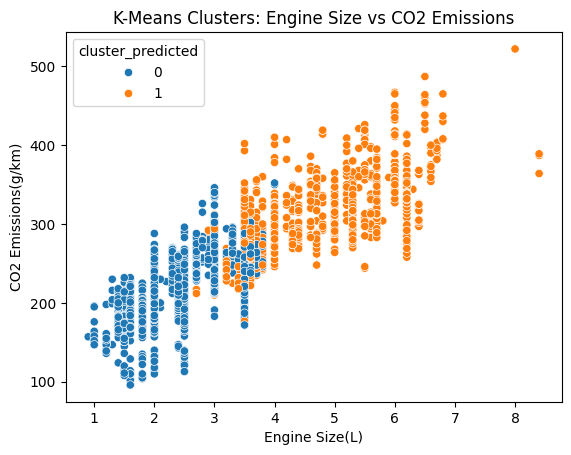

In [127]:
sns.scatterplot(data=train_clusters, x="Engine Size(L)", y="CO2 Emissions(g/km)", hue="cluster_predicted")
plt.title("K-Means Clusters: Engine Size vs CO2 Emissions")

K-Means is unsupervised and does not predict CO2 Emissions. It groups vehicles by
similarity across features without using the target at all. We include it here as
a separate, independent check: if unsupervised clusters (formed without any
knowledge of CO2 Emissions) still show distinct average CO2 by cluster, that's
supporting evidence that our supervised models found a genuine structural pattern,
not a modeling artifact.

## <font color='lightblue'>5. Interpreting the model</font>

In [119]:
# Random Forest  compare train vs test performance
y_pred_train = rf_model.predict(X_train)
r2_train = r2_score(y_train, y_pred_train)
print(f"RF Train R²: {r2_train:.4f}  |  RF Test R²: {r2:.4f}")

# Linear Regression - compare train vs test performance
y_pred_train_lr = lr_model.predict(X_train)
r2_train_lr = r2_score(y_train, y_pred_train_lr)
print(f"LR Train R²: {r2_train_lr:.4f}  |  LR Test R²: {r2_lr:.4f}")

RF Train R²: 0.9515  |  RF Test R²: 0.9318
LR Train R²: 0.7789  |  LR Test R²: 0.7715


To check generalization, we compared each model's performance on the training data versus the test data. Random Forest scored R² = 0.9515 on training data and R² = 0.9318 on test data, a gap of only 0.02 while Linear Regression scored R² = 0.7789 on training data and R² = 0.7715 on test data, a gap of 0.007

In [120]:
from sklearn.inspection import permutation_importance
feature_impo = permutation_importance(rf_model, x_test, y_test, n_repeats=10, random_state=42, n_jobs=2)

df_feature_impo = pd.DataFrame({
    "feature": x_test.columns,
    "importance": feature_impo.importances_mean
}).sort_values(by="importance", ascending=False)

df_feature_impo

,feature,importance
1,Engine Size(L),1.334866
0,Vehicle Class,0.213010
3,Transmission,0.114566
4,Fuel Type,0.068565
2,Cylinders,0.037447



Permutation importance shows that Engine Size(L) is overwhelmingly the strongest
predictor of CO2 emissions (importance = 1.33), followed by Vehicle Class (0.21),
Transmission (0.11), Fuel Type (0.07), and Cylinders (0.04). This makes physical
sense: larger engines burn more fuel per kilometre, which directly increases CO2
output. Because our final feature set excludes fuel consumption entirely, this
result reflects genuine design characteristics

## <font color='lightblue'>6. Answering the question</font>

Our original question was which vehicle characteristics are linked to higher CO2
emissions, with the goal of suggesting design changes to lower Canada's vehicle
carbon footprint.

Our analysis found that Engine Size and Vehicle Class are the dominant drivers of
CO2 emissions among the design characteristics we tested, with our Random Forest
model explaining 93.18% of the variance in emissions (test R² = 0.9318, MAE = 11.06
g/km) using only Engine Size, Vehicle Class, Cylinders, Transmission, and Fuel Type
deliberately excluding fuel consumption and mpg, since those are outcomes of
design choices rather than levers a designer can directly change.

We achieved our desired outcome: Engine Size is clearly the most actionable lever
available in this dataset, meaning a shift toward smaller-displacement engines
would have the largest direct impact on emissions.
